# 葡萄牙银行电话营销：定期存款认购预测

全文结构如下：

1. 数据探索
2. 数据划分和预处理
3. 三个基线模型
4. 决策树最大深度实验
5. 补充实验：duration 和类别权重
6. 模型选择
7. 阈值分析
8. 结论

做法说明：

- 比较模型和选参数只用训练集上的交叉验证（5 折分层，重复 3 次）。
- 选模型时没有看测试集的结果。阈值只在训练集的折外预测上选，测试集只用来报告。
- 随机种子都设成 42。

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_predict,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

## 1. 数据探索

### 1.1 数据基本情况

数据一共 4521 行、17 列（16 个特征加上目标变量 `y`）。没有缺失值，也没有重复的样本，所以不用删除或补全。

数值特征有 7 个：`age`、`balance`、`day`、`duration`、`campaign`、`pdays`、`previous`。类别特征有 9 个：`job`、`marital`、`education`、`default`、`housing`、`loan`、`contact`、`month`、`poutcome`。

买了定期存款的有 521 人，占 11.52%，没买的占 88.48%，数据很不平衡。如果模型全部预测成"不买"，准确率也有 88.48%，所以这个作业不能只看 Accuracy，我主要看 Recall、Precision、F1 和 PR-AUC。

类别里的 `unknown` 表示没有记录，但是具有有意义，比如 `poutcome=unknown` 是没被联系过的人，所以我把 `unknown` 当成单独的一类。

In [2]:
df = pd.read_csv("bank.csv", sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
print("样本数:", len(df), " 列数:", df.shape[1])
print("缺失值总数:", int(df.isna().sum().sum()))
print("完全重复的样本数:", int(df.duplicated().sum()))
df.dtypes

样本数: 4521  列数: 17
缺失值总数: 0
完全重复的样本数: 0


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [4]:
df["y"] = df["y"].map({"yes": 1, "no": 0})
target_dist = df["y"].value_counts().to_frame("count")
target_dist["ratio"] = target_dist["count"] / len(df)
target_dist

,count,ratio
y,,
0,4000,0.88476
1,521,0.11524


In [5]:
num_raw = df.drop(columns="y").select_dtypes(include="number").columns.tolist()
cat_raw = df.drop(columns="y").select_dtypes(exclude="number").columns.tolist()
print(f"数值特征（{len(num_raw)} 个）:", num_raw)
print(f"类别特征（{len(cat_raw)} 个）:", cat_raw)

数值特征（7 个）: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
类别特征（9 个）: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [6]:
for col in cat_raw:
    print("-" * 40)
    print(df[col].value_counts())

----------------------------------------
job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
unknown           38
Name: count, dtype: int64
----------------------------------------
marital
married     2797
single      1196
divorced     528
Name: count, dtype: int64
----------------------------------------
education
secondary    2306
tertiary     1350
primary       678
unknown       187
Name: count, dtype: int64
----------------------------------------
default
no     4445
yes      76
Name: count, dtype: int64
----------------------------------------
housing
yes    2559
no     1962
Name: count, dtype: int64
----------------------------------------
loan
no     3830
yes     691
Name: count, dtype: int64
----------------------------------------
contact
cellular     2896
unknown      1324
telephone     301
Name:

In [7]:
df[num_raw].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,4521.0,41.17,10.58,19.0,33.0,39.0,49.0,87.0
balance,4521.0,1422.66,3009.64,-3313.0,69.0,444.0,1480.0,71188.0
day,4521.0,15.92,8.25,1.0,9.0,16.0,21.0,31.0
duration,4521.0,263.96,259.86,4.0,104.0,185.0,329.0,3025.0
campaign,4521.0,2.79,3.11,1.0,1.0,2.0,3.0,50.0
pdays,4521.0,39.77,100.12,-1.0,-1.0,-1.0,-1.0,871.0
previous,4521.0,0.54,1.69,0.0,0.0,0.0,0.0,25.0


In [8]:
df[num_raw].skew().round(2).sort_values(ascending=False).to_frame("skewness")

,skewness
balance,6.60
previous,5.88
campaign,4.74
duration,2.77
pdays,2.72
age,0.70
day,0.09


In [9]:
print("pdays = -1 的比例: %.2f%%" % ((df["pdays"] == -1).mean() * 100))
df.loc[df["pdays"] != -1].groupby("y")["pdays"].describe().round(1)

pdays = -1 的比例: 81.95%


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
0,632.0,233.2,111.8,2.0,150.0,215.5,335.2,871.0
1,184.0,196.2,130.3,1.0,95.0,181.0,262.2,804.0


In [10]:
pd.crosstab(df["pdays"] == -1, df["poutcome"], margins=True)

poutcome,failure,other,success,unknown,All
pdays,,,,,
False,490,197,129,0,816
True,0,0,0,3705,3705
All,490,197,129,3705,4521


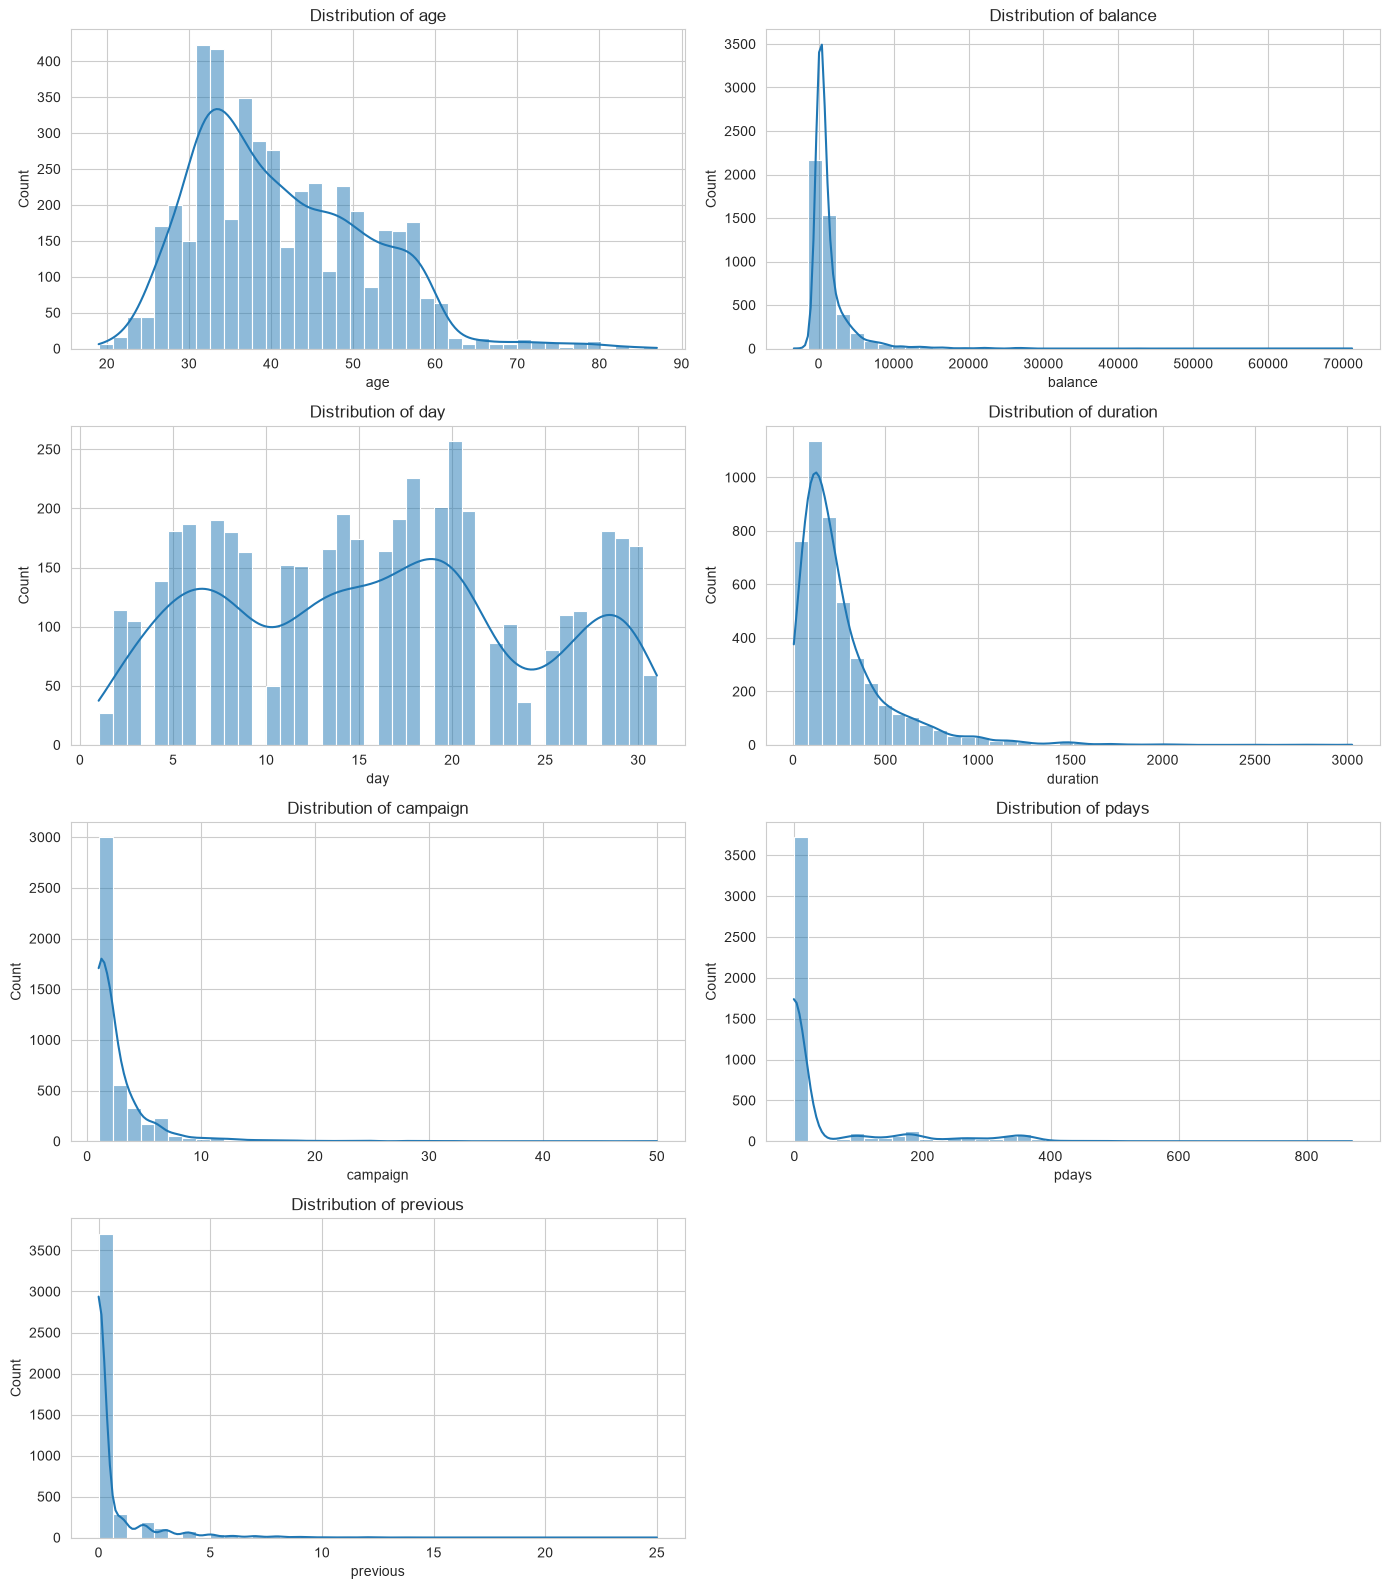

In [11]:
df_eda = df.copy()

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for ax, col in zip(axes, num_raw):
    sns.histplot(data=df_eda, x=col, bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [12]:
df.groupby("y")[num_raw].agg(["mean", "median", "std"]).T.round(2)

y                      0        1
age      mean      41.00    42.49
         median    39.00    40.00
         std       10.19    13.12
balance  mean    1403.21  1571.96
         median   419.50   710.00
         std     3075.35  2444.40
day      mean      15.95    15.66
         median    16.00    15.00
         std        8.25     8.24
duration mean     226.35   552.74
         median   167.00   442.00
         std      210.31   390.33
campaign mean       2.86     2.27
         median     2.00     2.00
         std        3.21     2.09
pdays    mean      36.01    68.64
         median    -1.00    -1.00
         std       96.30   121.96
previous mean       0.47     1.09
         median     0.00     0.00
         std        1.63     2.06

In [13]:
duration_bins = [0, 60, 120, 180, 300, 600, np.inf]
duration_labels = ["<=60", "61-120", "121-180", "181-300", "301-600", ">600"]
df_eda["duration_bin"] = pd.cut(
    df_eda["duration"], bins=duration_bins, labels=duration_labels, include_lowest=True
)
duration_analysis = (
    df_eda.groupby("duration_bin", observed=False)["y"]
    .agg(sample_count="size", yes_rate="mean")
    .reset_index()
)
duration_analysis

,duration_bin,sample_count,yes_rate
0,<=60,492,0.002033
1,61-120,887,0.024803
2,121-180,833,0.039616
3,181-300,1046,0.104207
4,301-600,841,0.197384
5,>600,422,0.450237


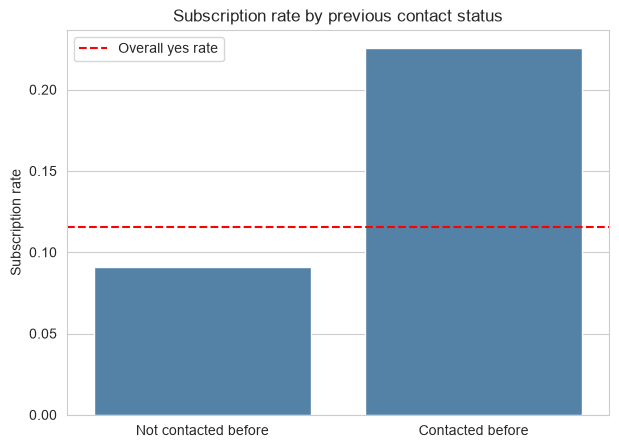

,previously_contacted,sample_count,yes_rate
0,0,3705,0.090958
1,1,816,0.225490


In [14]:
df_eda["previously_contacted"] = (df_eda["pdays"] != -1).astype(int)
prev_analysis = (
    df_eda.groupby("previously_contacted")["y"]
    .agg(sample_count="size", yes_rate="mean")
    .reset_index()
)

plt.figure(figsize=(7, 5))
sns.barplot(data=prev_analysis, x="previously_contacted", y="yes_rate", color="steelblue")
plt.axhline(df_eda["y"].mean(), color="red", linestyle="--", label="Overall yes rate")
plt.xticks(ticks=[0, 1], labels=["Not contacted before", "Contacted before"])
plt.title("Subscription rate by previous contact status")
plt.xlabel("")
plt.ylabel("Subscription rate")
plt.legend()
plt.show()
prev_analysis

### 1.2 数值特征

- `balance`、`previous`、`campaign`、`duration`、`pdays` 的偏度都比较大（分别是 6.6、5.9、4.7、2.8、2.7），是明显的右偏分布。`age` 和 `day` 基本对称。`balance` 最小是 -3313，说明有人透支。
- `pdays` 里有 81.95% 是 -1，意思是之前没被联系过。这些人的 `poutcome` 全是 `unknown`，两列正好对上（3705 条）。-1 只是一个编码，如果直接算均值，结果会被 -1 拉偏（36 vs 68），没有参考价值。只看被联系过的 816 人，买了的人 `pdays` 中位数是 181，没买的是 215.5，也就是说最近才联系过的人更容易买。
- 买了的人通话时间明显更长（平均 553 秒，没买的是 226 秒），是区分最明显的数值变量。不过通话时间是打完电话才知道的，拨号前用不了，后面会专门讨论。
- 通话不到 60 秒的客户，买的比例只有 0.20%；超过 600 秒的有 45.02%。
- 之前被联系过的客户买的比例是 22.55%，没被联系过的是 9.10%。
- 买了的人 `campaign` 均值更小（2.27 对 2.86）。这可能是打得越多效果越差，也可能是难打动的人会被多打几次，从这张表看不出是哪一种。
- `balance` 的中位数也有差距（买的 710 欧，没买的 420 欧）。`age` 两组的均值只差 1.5 岁，看不出年龄有明显影响。
- `previous` 的均值差得比较多（1.09 对 0.47），但两组中位数都是 0。这个差距主要来自"之前被联系过"的那部分人，和 `previously_contacted` 的信息是重复的。

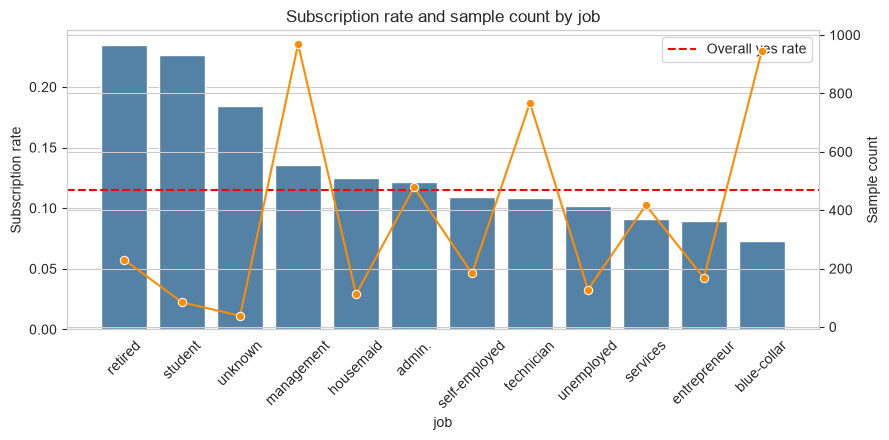

,job,sample_count,yes_rate
5,retired,230,0.2348
8,student,84,0.2262
11,unknown,38,0.1842
4,management,969,0.1352
3,housemaid,112,0.1250
0,admin.,478,0.1213
6,self-employed,183,0.1093
9,technician,768,0.1081
10,unemployed,128,0.1016
7,services,417,0.0911


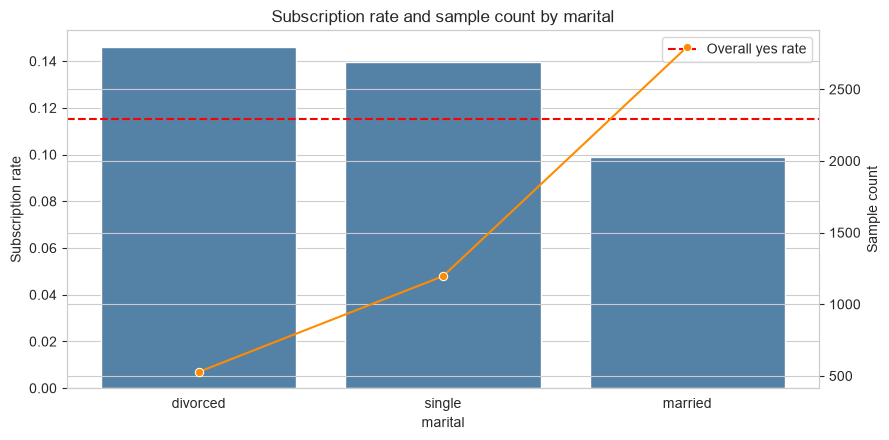

,marital,sample_count,yes_rate
0,divorced,528,0.1458
2,single,1196,0.1396
1,married,2797,0.0990


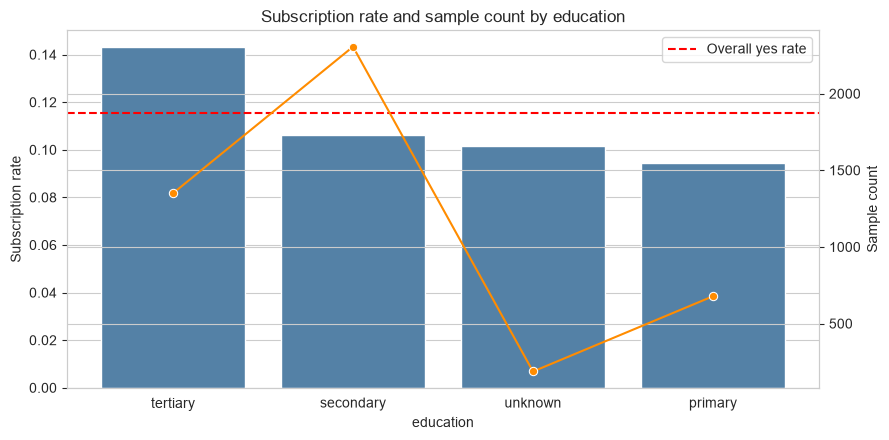

,education,sample_count,yes_rate
2,tertiary,1350,0.1430
1,secondary,2306,0.1062
3,unknown,187,0.1016
0,primary,678,0.0944


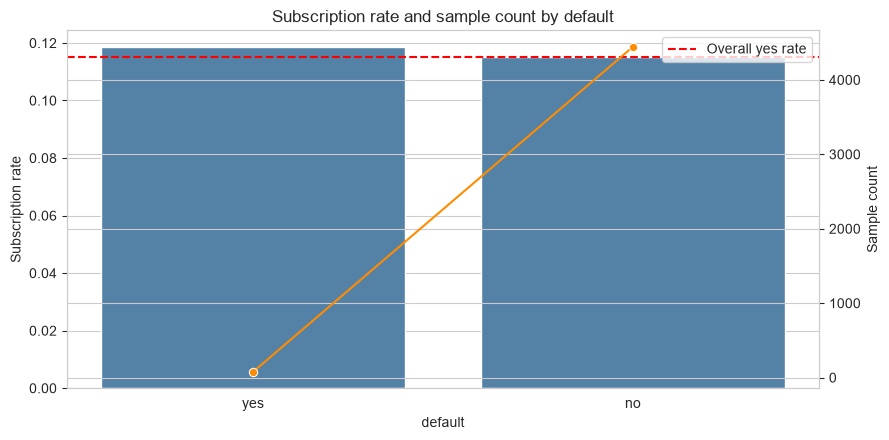

,default,sample_count,yes_rate
1,yes,76,0.1184
0,no,4445,0.1152


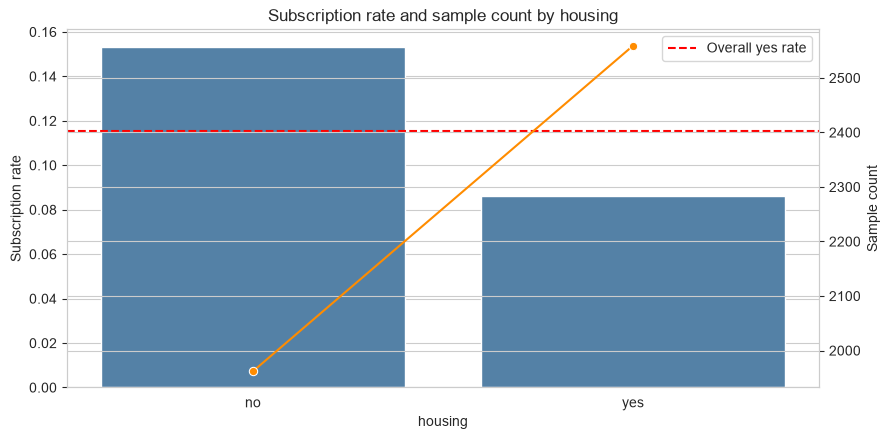

,housing,sample_count,yes_rate
0,no,1962,0.1534
1,yes,2559,0.0860


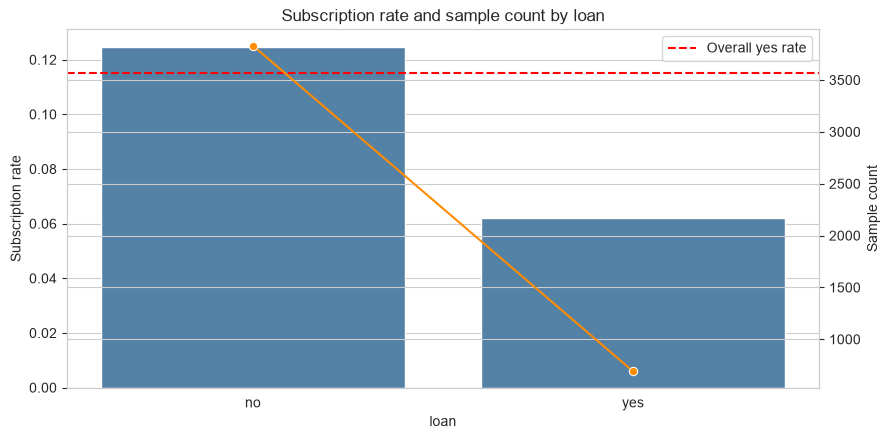

,loan,sample_count,yes_rate
0,no,3830,0.1248
1,yes,691,0.0622


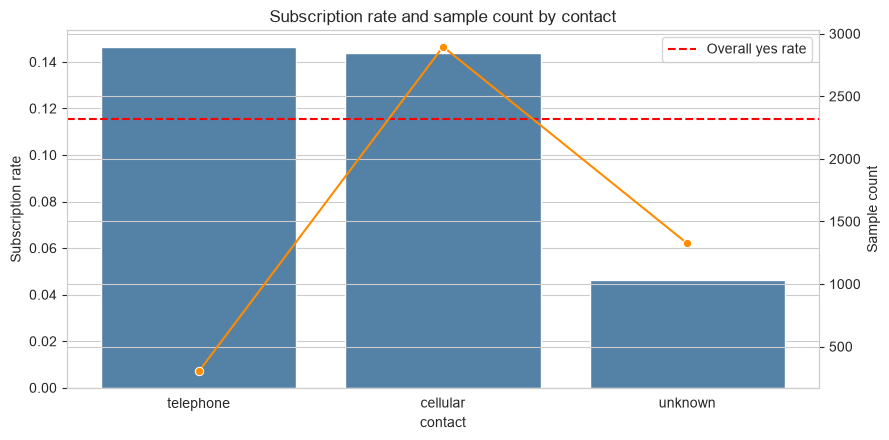

,contact,sample_count,yes_rate
1,telephone,301,0.1462
0,cellular,2896,0.1436
2,unknown,1324,0.0461


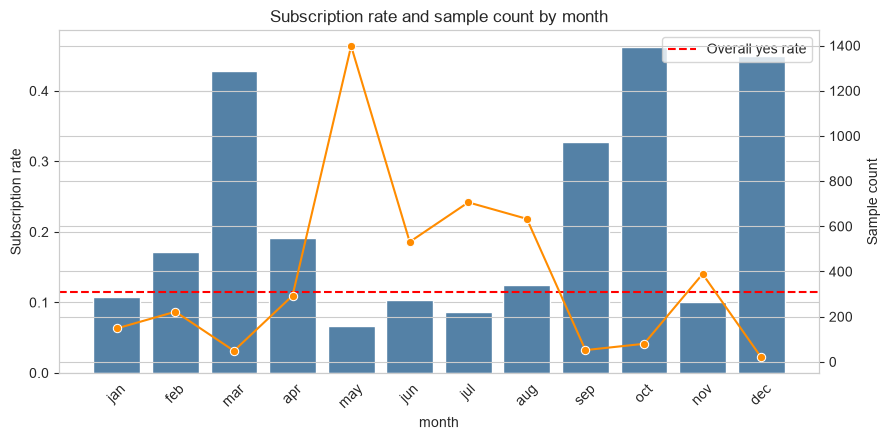

,month,sample_count,yes_rate
0,jan,148,0.1081
1,feb,222,0.1712
2,mar,49,0.4286
3,apr,293,0.1911
4,may,1398,0.0665
5,jun,531,0.1036
6,jul,706,0.0864
7,aug,633,0.1248
8,sep,52,0.3269
9,oct,80,0.4625


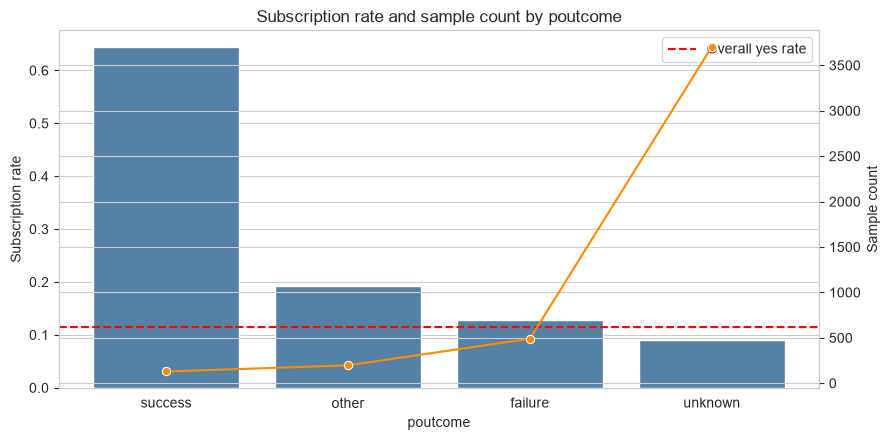

,poutcome,sample_count,yes_rate
2,success,129,0.6434
1,other,197,0.1929
0,failure,490,0.1286
3,unknown,3705,0.0910


In [15]:
def plot_yes_rate(data, column, order=None, rotation=0):
    result = data.groupby(column)["y"].agg(sample_count="size", yes_rate="mean").reset_index()
    if order is None:
        result = result.sort_values("yes_rate", ascending=False)
    else:
        result = result.set_index(column).loc[order].reset_index()

    fig, ax1 = plt.subplots(figsize=(9, 4.5))
    sns.barplot(data=result, x=column, y="yes_rate", ax=ax1, color="steelblue")
    ax1.axhline(data["y"].mean(), color="red", linestyle="--", label="Overall yes rate")
    ax1.set_ylabel("Subscription rate")
    ax1.set_xlabel(column)
    ax1.tick_params(axis="x", rotation=rotation)
    ax1.legend(loc="upper right")

    ax2 = ax1.twinx()
    sns.lineplot(data=result, x=column, y="sample_count", ax=ax2, color="darkorange", marker="o")
    ax2.set_ylabel("Sample count")
    ax1.set_title(f"Subscription rate and sample count by {column}")
    plt.tight_layout()
    plt.show()
    return result


MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
cat_results = {}
for col in cat_raw:
    order = MONTH_ORDER if col == "month" else None
    cat_results[col] = plot_yes_rate(df_eda, col, order=order, rotation=45 if col in ["job", "month"] else 0)
    display(cat_results[col].round(4))

### 1.3 类别特征

- 职业：退休人员（23.5%）和学生（22.6%）买的比例高，蓝领最低（7.3%）。
- 婚姻：离婚（14.6%）和单身（14.0%）比已婚（9.9%）高。
- 教育：大学学历最高（14.3%），`unknown` 是 10.2%。
- 贷款：没有住房贷款的买的比例是 15.3%，有的是 8.6%；没有个人贷款的是 12.5%，有的是 6.2%。欠贷款的人买得少，这和常识差不多。
- 联系方式：telephone（14.6%）和 cellular（14.4%）差不多，`unknown` 只有 4.6%。
- 上次营销的结果：`success` 的人有 64.34% 买了，比其他类别高很多，但只有 129 条。`unknown` 占了 82%。
- `default`：只有 76 人是 yes，买的比例和 no 几乎一样（11.8% 对 11.5%），这个变量看起来没什么用。
- 月份：3、9、10、12 月的购买率很高（42.9%、32.7%、46.3%、45.0%），但每个月只有 20 到 80 条，不能说明什么季节规律。样本最多的 5 月有 1398 条，购买率只有 6.7%。

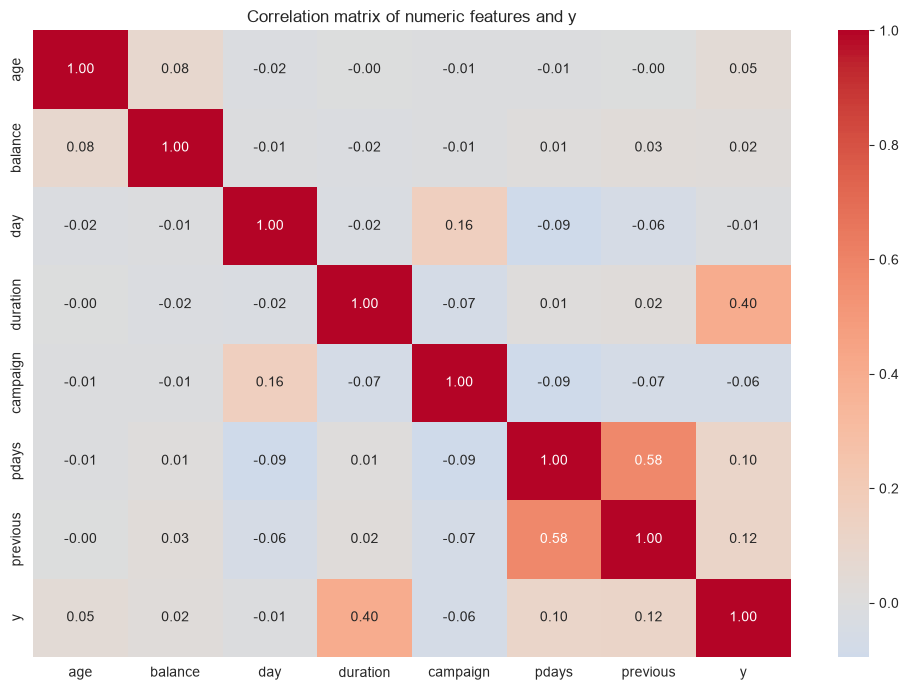

In [16]:
corr = df_eda[num_raw + ["y"]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation matrix of numeric features and y")
plt.tight_layout()
plt.show()

### 1.4 小结

数据是完整的，但标签不平衡，所以后面主要看 Recall、F1 和 PR-AUC。`duration` 的区分度最强，但它不能用于拨号前的筛选。`pdays=-1` 需要单独处理，所以我构造了 `previously_contacted`。`unknown` 保留成一个类别。数值变量的偏度比较大，建模前需要做变换。

## 2. 数据划分与预处理

**划分** 用 `train_test_split` 按 8:2 划分，训练集 3616 条，测试集 905 条。加了 `stratify=y`，这样两边的买入比例都接近 11.5%（训练集 11.53%，测试集 11.49%）。随机种子是 42。之后所有拟合（标准化、幂变换、独热编码、模型训练）都只用训练集。

**特征处理**

- 新增 `previously_contacted`：`pdays` 不是 -1 就是 1，否则是 0。
- `pdays` 里的 -1 改成 0。有了 `previously_contacted` 之后，0 只表示"没被联系过"，不会被当成真实天数。
- `balance`、`duration`、`campaign`、`pdays`、`previous` 这五个偏态变量用 Yeo-Johnson 幂变换。这个方法同时会做标准化，而且能处理负数（`balance` 里有负数）。
- `age` 和 `day` 只做标准化。
- 类别变量做独热编码，`handle_unknown="ignore"`。

**交叉验证** 预处理和模型放在同一个 `Pipeline` 里，每一折只用这一折的训练部分去拟合预处理器，验证部分只做变换。这样验证集的信息就不会影响预处理的参数。交叉验证是 5 折分层，重复 3 次，一共 15 次划分。

In [17]:
X = df.drop(columns="y").copy()
y = df["y"].copy()

X["previously_contacted"] = (X["pdays"] != -1).astype(int)
X["pdays"] = X["pdays"].where(X["pdays"] != -1, 0)

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_without_duration = [c for c in num_features if c != "duration"]
print("数值特征:", num_features)
print("类别特征:", cat_features)

数值特征: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'previously_contacted']
类别特征: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"训练集: {X_train.shape[0]} 条, 认购比例 {y_train.mean():.4f}")
print(f"测试集: {X_test.shape[0]} 条, 认购 {y_test.sum()} 条, 认购比例 {y_test.mean():.4f}")

训练集: 3616 条, 认购比例 0.1153
测试集: 905 条, 认购 104 条, 认购比例 0.1149


In [19]:
SKEWED_FEATURES = ["balance", "duration", "campaign", "pdays", "previous"]
METRIC_NAMES = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
}
SCORING = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


def make_preprocessor(num_cols, cat_cols):
    skewed = [c for c in num_cols if c in SKEWED_FEATURES]
    plain = [c for c in num_cols if c not in SKEWED_FEATURES + ["previously_contacted"]]
    return ColumnTransformer(
        transformers=[
            ("skewed", PowerTransformer(method="yeo-johnson"), skewed),
            ("scaled", StandardScaler(), plain),
            ("flag", "passthrough", ["previously_contacted"]),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ]
    )


def make_pipeline(model, num_cols):
    return Pipeline([("prep", make_preprocessor(num_cols, cat_features)), ("model", model)])


def make_model(name, class_weight=None, depth=None):
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=RANDOM_STATE)
    if name == "Decision Tree":
        return DecisionTreeClassifier(max_depth=depth, class_weight=class_weight, random_state=RANDOM_STATE)
    if name == "SVM (RBF)":
        return SVC(kernel="rbf", probability=True, class_weight=class_weight, random_state=RANDOM_STATE)
    raise ValueError(name)


def cv_eval(pipe, X_tr, y_tr):
    res = cross_validate(
        pipe, X_tr, y_tr, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1
    )
    out = {f"CV {METRIC_NAMES[k]}": res[f"test_{k}"].mean() for k in SCORING}
    out["CV F1 std"] = res["test_f1"].std()
    out["Train F1"] = res["train_f1"].mean()
    return out, res


def test_eval(fitted, X_te, y_te):
    pred = fitted.predict(X_te)
    proba = fitted.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1": f1_score(y_te, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, proba),
        "PR-AUC": average_precision_score(y_te, proba),
    }

## 3. 三个基线模型

三个模型用的是同样的特征（包括 `duration`）和同样的预处理，参数基本用默认值：逻辑回归 `max_iter=2000`，决策树不限深度，SVM 用 RBF 核。这一节主要是给后面的比较找一个起点。

In [20]:
baseline_names = ["Logistic Regression", "Decision Tree", "SVM (RBF)"]
baseline_cv, baseline_test, baseline_fitted = [], [], {}

for name in baseline_names:
    pipe = make_pipeline(make_model(name), num_features)
    cv_out, _ = cv_eval(pipe, X_train, y_train)
    baseline_cv.append({"Model": name, **cv_out})

    pipe.fit(X_train, y_train)
    baseline_fitted[name] = pipe
    baseline_test.append({"Model": name, **test_eval(pipe, X_test, y_test)})

baseline_cv_df = pd.DataFrame(baseline_cv)
baseline_test_df = pd.DataFrame(baseline_test)
print("训练集交叉验证结果（5 折 × 3 次）")
display(baseline_cv_df.round(4))
print("测试集结果")
display(baseline_test_df.round(4))

训练集交叉验证结果（5 折 × 3 次）


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC,CV F1 std,Train F1
0,Logistic Regression,0.9014,0.6349,0.3494,0.4478,0.8942,0.5271,0.0512,0.4826
1,Decision Tree,0.8689,0.4365,0.4539,0.4433,0.6885,0.2619,0.0393,1.0000
2,SVM (RBF),0.8958,0.6757,0.1847,0.2870,0.8782,0.5211,0.0669,0.4212


测试集结果


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8917,0.5556,0.2885,0.3797,0.8918,0.4822
1,Decision Tree,0.8497,0.3730,0.4519,0.4087,0.6766,0.2316
2,SVM (RBF),0.8972,0.6897,0.1923,0.3008,0.8740,0.4978


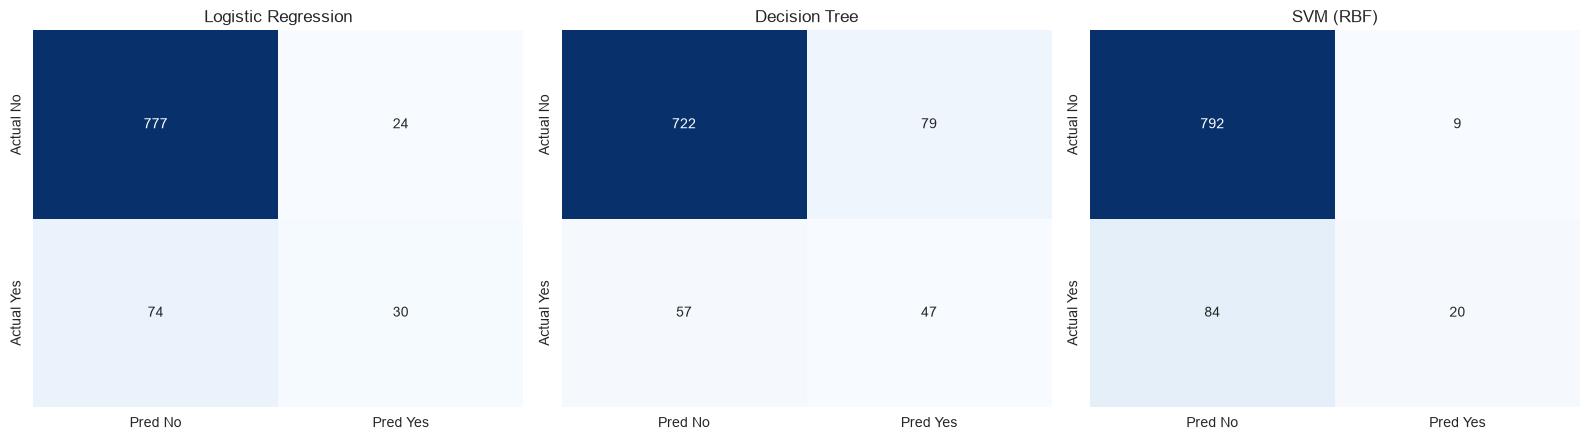

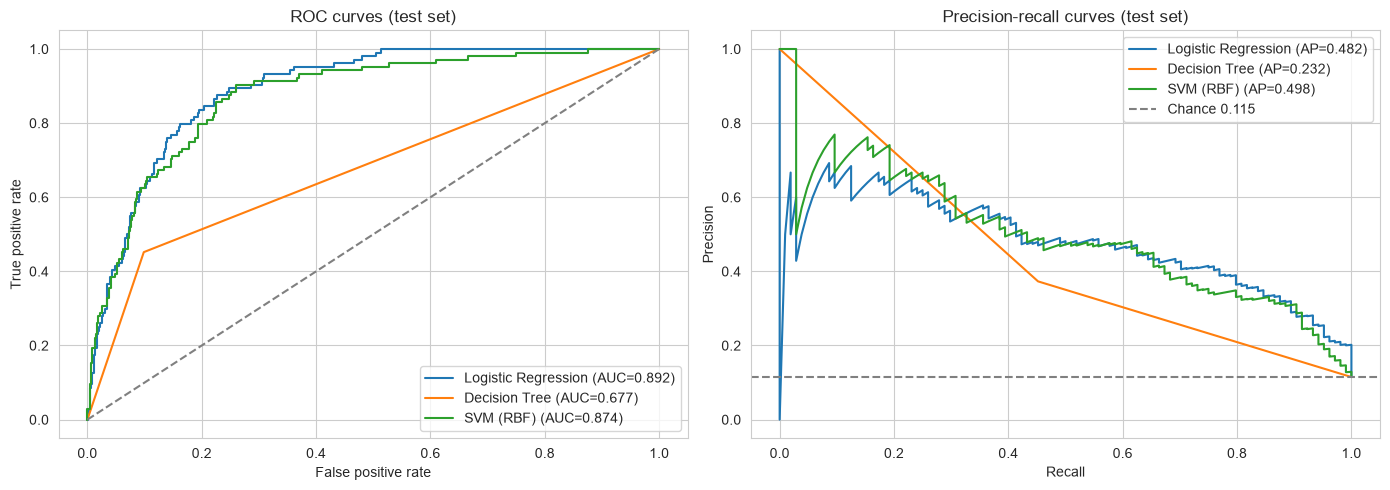

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, baseline_names):
    pred = baseline_fitted[name].predict(X_test)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"],
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in baseline_names:
    proba = baseline_fitted[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)")
axes[0].legend()
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label=f"Chance {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

先看交叉验证结果（训练集上 15 次划分的平均）。逻辑回归的 CV F1 是 0.4478，SVM 是 0.2870。两者差距主要来自 Recall：SVM 只找到了 18% 的买家（Recall 0.1847），但它的 Precision 有 0.68，说明它只标出了很有把握的少数人。两者的 PR-AUC 很接近（逻辑回归 0.5271，SVM 0.5211），所以排序能力差不多，差别主要在默认阈值下的判定上。

决策树的训练集 F1 是 1.0，CV F1 只有 0.4433，这是典型的过拟合。它和逻辑回归的 CV F1 几乎持平。

再看测试集。三个模型的 F1 是决策树（0.4087）、逻辑回归（0.3797）、SVM（0.3008）。决策树在测试集上领先，但 CV 里它和逻辑回归差得很少，而测试集只有 104 个买家，这点差距不能说明决策树更好。

把三个模型放在一起看，有几点比较明显：

- Accuracy 在 0.85 到 0.90 之间，但 88.5% 的样本是不买的，所以 Accuracy 没有区分度。
- Recall 只有 0.19 到 0.45，说明默认阈值下大多数买家都没有被找到。
- 决策树的 Recall 最高（0.45），但它的 ROC-AUC（0.6766）和 PR-AUC（0.2316）都是三个里最低的。它的 Precision 只有 0.37，说明 Recall 是靠大量误报换来的。
- 逻辑回归的 ROC-AUC 最高（0.8918），SVM 的 PR-AUC 最高（0.4978）。两者的排序能力都不错。
- SVM 的 Precision 最高（0.69），但 Recall 最低（0.19），属于很保守的判定。

所以问题不太像是模型排序能力不够，而是默认阈值 0.5 下的判定位置不合适，尤其对 SVM 和逻辑回归影响很大。第 7 节会专门看阈值的影响。

## 4. 决策树最大深度实验

这一节选决策树，研究参数 `max_depth`。取值是 1、2、3、4、5、7、10、15 和不限制，一共 9 个。

问题是：树越深，模型会不会从欠拟合变成过拟合？CV F1 最高的那个深度，是不是就应该选它？

选深度的规则：先找 CV F1 最高的深度，再算它减去一个标准差的值。CV F1 不低于这个值的深度，认为效果差不多，从里面选最浅的那个。原因是不同深度之间的差距有时比交叉验证的波动还小，直接选最大值不太可靠。

判断过拟合和欠拟合，看训练集 F1 和 CV F1 的差距（Train-CV gap）。两个都低就是欠拟合，训练集很高但 CV 很低就是过拟合。另外我还记录了每个深度里 F1 等于 0 的折数，用来解释结果为什么不稳定。

In [22]:
depth_candidates = [1, 2, 3, 4, 5, 7, 10, 15, None]
depth_rows = []

for d in depth_candidates:
    pipe = make_pipeline(make_model("Decision Tree", depth=d), num_features)
    out, res = cv_eval(pipe, X_train, y_train)
    depth_rows.append({
        "max_depth": "None" if d is None else d,
        "Train F1": out["Train F1"],
        "CV F1": out["CV F1"],
        "CV F1 std": out["CV F1 std"],
        "Train-CV gap": out["Train F1"] - out["CV F1"],
        "CV Precision": out["CV Precision"],
        "CV Recall": out["CV Recall"],
        "CV ROC-AUC": out["CV ROC-AUC"],
        "CV PR-AUC": out["CV PR-AUC"],
        "F1=0 folds": int((res["test_f1"] == 0).sum()),
    })

depth_df = pd.DataFrame(depth_rows)
depth_df["_order"] = [1e6 if d is None else d for d in depth_candidates]
display(depth_df.round(4).drop(columns="_order"))

,max_depth,Train F1,CV F1,CV F1 std,Train-CV gap,CV Precision,CV Recall,CV ROC-AUC,CV PR-AUC,F1=0 folds
0,1,0.3123,0.2974,0.1810,0.0149,0.3637,0.2532,0.6529,0.2472,4
1,2,0.4796,0.4594,0.0414,0.0202,0.5967,0.3774,0.7233,0.3611,0
2,3,0.4895,0.4346,0.0302,0.0549,0.6207,0.3390,0.7684,0.4023,0
3,4,0.5458,0.4321,0.0577,0.1136,0.5949,0.3470,0.7967,0.4113,0
4,5,0.5781,0.4242,0.0677,0.1539,0.5968,0.3356,0.7908,0.4034,0
5,7,0.6856,0.4475,0.0493,0.2381,0.5865,0.3653,0.7569,0.3873,0
6,10,0.8039,0.4501,0.0455,0.3538,0.5356,0.3907,0.6804,0.3467,0
7,15,0.9271,0.4436,0.0493,0.4835,0.4764,0.4187,0.6801,0.3040,0
8,None,1.0000,0.4433,0.0393,0.5567,0.4365,0.4539,0.6885,0.2619,0


In [23]:
best_row = depth_df.loc[depth_df["CV F1"].idxmax()]
one_std_line = best_row["CV F1"] - best_row["CV F1 std"]
eligible = depth_df[depth_df["CV F1"] >= one_std_line].sort_values("_order")
chosen = eligible.iloc[0]
BEST_DEPTH = None if chosen["max_depth"] == "None" else int(chosen["max_depth"])

print(f"CV F1 最高: max_depth={best_row['max_depth']}, CV F1={best_row['CV F1']:.4f}")
print(f"一个标准差下界: {one_std_line:.4f}")
print(f"选中的深度（满足条件的最浅者）: max_depth={chosen['max_depth']}, CV F1={chosen['CV F1']:.4f}")

CV F1 最高: max_depth=2, CV F1=0.4594
一个标准差下界: 0.4180
选中的深度（满足条件的最浅者）: max_depth=2, CV F1=0.4594


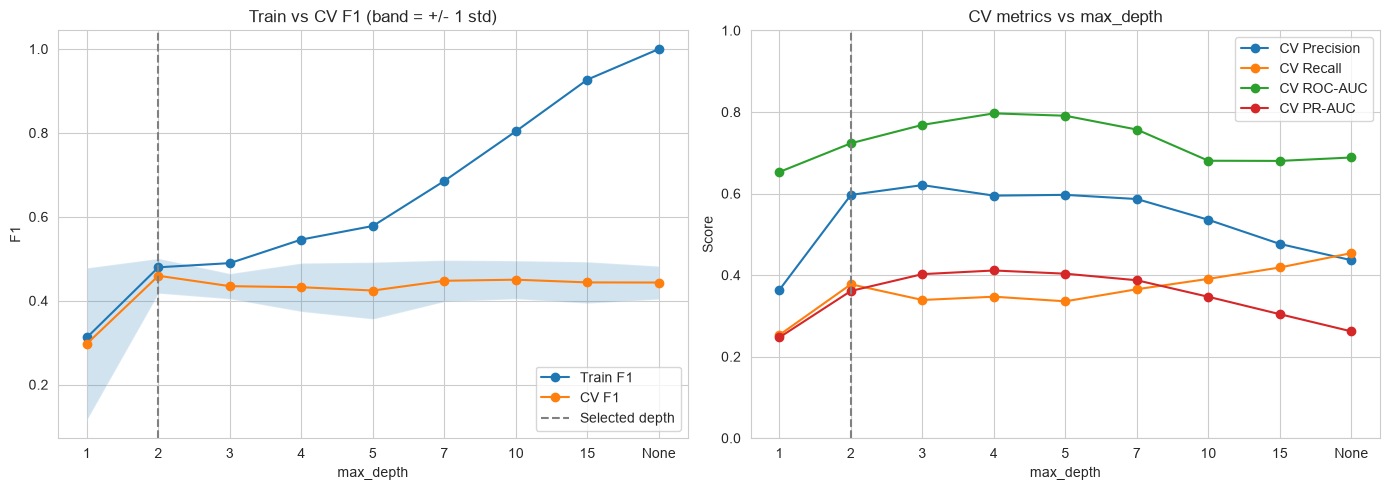

In [24]:
labels = depth_df["max_depth"].astype(str).tolist()
x = np.arange(len(labels))
chosen_idx = labels.index(str(chosen["max_depth"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(x, depth_df["Train F1"].to_numpy(), marker="o", label="Train F1")
axes[0].plot(x, depth_df["CV F1"].to_numpy(), marker="o", label="CV F1")
axes[0].fill_between(
    x,
    (depth_df["CV F1"] - depth_df["CV F1 std"]).to_numpy(),
    (depth_df["CV F1"] + depth_df["CV F1 std"]).to_numpy(),
    alpha=0.2,
)
axes[0].axvline(chosen_idx, linestyle="--", color="gray", label="Selected depth")
axes[0].set_xticks(x, labels)
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("F1")
axes[0].set_title("Train vs CV F1 (band = +/- 1 std)")
axes[0].legend()

for col in ["CV Precision", "CV Recall", "CV ROC-AUC", "CV PR-AUC"]:
    axes[1].plot(x, depth_df[col].to_numpy(), marker="o", label=col)
axes[1].axvline(chosen_idx, linestyle="--", color="gray")
axes[1].set_xticks(x, labels)
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].set_title("CV metrics vs max_depth")
axes[1].legend()
plt.tight_layout()
plt.show()

**欠拟合。** `max_depth=1` 时，训练集 F1 是 0.3123，CV F1 是 0.2974，两个都很低。15 次划分里有 4 次 F1 直接是 0，也就是模型在那几次里一个买家都没预测出来。树只分了一次，只能用一个条件区分客户，太简单了，所以结果很不稳定（标准差 0.181，其他深度的标准差是 0.03 到 0.07）。

**过拟合。** 深度越大，训练集 F1 涨得很快，从深度 2 的 0.48 涨到不限深度的 1.00。但 CV F1 一直在 0.42 到 0.46 之间，没有明显提高。Train-CV gap 从深度 2 的 0.02 涨到深度 4 的 0.11、深度 10 的 0.35，不限深度时是 0.56。深度超过 5 以后，树基本上是在记训练集。

**最后选的深度。** CV F1 最高的是深度 2（0.4594），减去一个标准差是 0.4180。除了深度 1，其他深度都在这个范围里，但深度 2 最浅，所以选 `max_depth=2`。它的 Train-CV gap 只有 0.02，过拟合不严重。后面的实验都用这个深度。

**需要注意的地方。** 如果看 ROC-AUC 和 PR-AUC，最好的是深度 4（ROC-AUC 0.7967，PR-AUC 0.4113）。F1 是在阈值 0.5 下算的，而 ROC-AUC 和 PR-AUC 不依赖阈值。也就是说深度 4 的排序能力更强，但在 0.5 阈值下 Precision 和 Recall 不如深度 2 平衡。这个作业我最关心的是默认阈值下的分类效果，所以选了深度 2。如果以后只是想给客户排序，深度 4 会更合适。

### 4.1 学习曲线

前面调的是树的深度。现在通过学习曲线来看一下数据量够不够。我把训练集从 10% 到 100% 分成 10 档，每档做 5 折交叉验证，看训练 F1 和验证 F1 怎么随数据量变化。树用的是刚才选的 `max_depth=2`。

,train size,train F1,val F1,val F1 std
0,289,0.6050,0.4181,0.0885
1,578,0.3634,0.2803,0.0922
2,867,0.3675,0.3372,0.1155
3,1156,0.4380,0.4403,0.0138
4,1446,0.4302,0.4377,0.0198
5,1735,0.4488,0.4557,0.0226
6,2024,0.4199,0.3967,0.1191
7,2313,0.4936,0.4659,0.0300
8,2602,0.4880,0.4651,0.0267
9,2892,0.4902,0.4723,0.0342


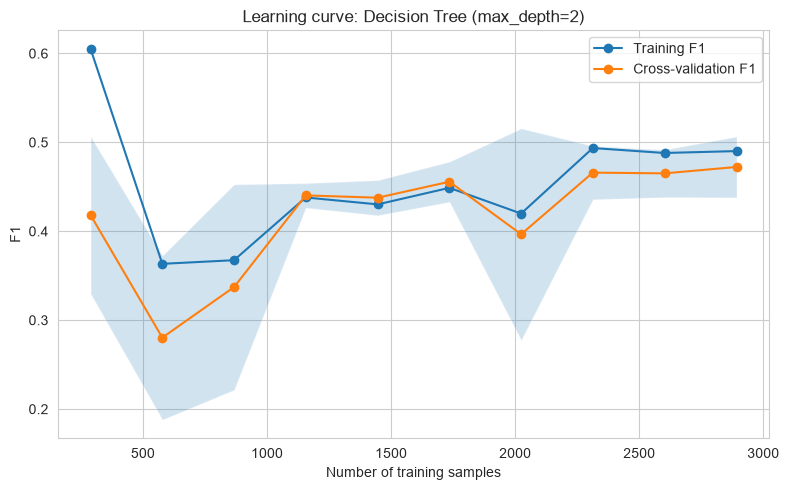

In [25]:
pipe_lc = make_pipeline(make_model("Decision Tree", depth=BEST_DEPTH), num_features)

train_sizes, train_scores, val_scores = learning_curve(
    pipe_lc,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring=make_scorer(f1_score, zero_division=0),
    n_jobs=-1,
)

lc_df = pd.DataFrame({
    "train size": train_sizes.astype(int),
    "train F1": train_scores.mean(axis=1),
    "val F1": val_scores.mean(axis=1),
    "val F1 std": val_scores.std(axis=1),
})
display(lc_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Training F1")
plt.plot(train_sizes, val_scores.mean(axis=1), marker="o", label="Cross-validation F1")
plt.fill_between(
    train_sizes,
    val_scores.mean(axis=1) - val_scores.std(axis=1),
    val_scores.mean(axis=1) + val_scores.std(axis=1),
    alpha=0.2,
)
plt.xlabel("Number of training samples")
plt.ylabel("F1")
plt.title(f"Learning curve: Decision Tree (max_depth={BEST_DEPTH})")
plt.legend()
plt.tight_layout()
plt.show()

- 300 条左右的时候结果很差，训练 F1 0.61、验证 F1 0.42，而且验证分数的波动很大（标准差 0.09）。数据太少的时候，连"训练得好不好"都说明不了问题。
- 从 1150 条左右开始，训练 F1 和验证 F1 就基本重合了（最后是 0.490 对 0.472），差距只有 0.02 左右。也就是说这棵深度 2 的树没有明显的过拟合，模型复杂度和数据量是匹配的。
- 验证 F1 一直在慢慢往上走，从 0.28 升到 0.47，说明加数据确实有用，但到后面涨幅很小（2700 条到 2900 条只升了 0.007）。再往下，曲线基本平了，数据翻倍大概也涨不了多少。
- 中间有一次波动比较大（2000 条附近标准差 0.12），因为每个档位里买家只有几十个，某一折的结果就能把平均值拉动很多。

所以对这棵深度 2 的树来说，问题不是数据不够，而是模型太简单（深度 2 只有两个判断条件）。想再提高，加数据的用处不大，要么加深树（但前面试过，容易过拟合），要么换别的模型，比如随机森林、梯度提升。

## 5. 第四问实验二：duration 和类别权重

这一节尝试探索两个问题：

- 问题 A：`duration` 是打完电话才知道的。如果把它去掉，模型会差多少？如果差很多，说明模型主要是靠通话结果在判断，那拨号前就不能用它。
- 问题 B：加上 `class_weight="balanced"` 能不能找到更多买家？代价是什么？

两个问题都在含 `duration` 和不含 `duration` 两套特征上，用三个模型、原始权重和加权各做一次交叉验证。决策树用的是第 4 节选出来的 `max_depth=2`。

In [26]:
feature_sets = {"with duration": num_features, "without duration": num_without_duration}
class_weights = {"original": None, "balanced": "balanced"}
exp_rows = []

for fs_name, num_cols in feature_sets.items():
    for name in baseline_names:
        for cw_name, cw in class_weights.items():
            depth = BEST_DEPTH if name == "Decision Tree" else None
            pipe = make_pipeline(make_model(name, class_weight=cw, depth=depth), num_cols)
            out, _ = cv_eval(pipe, X_train, y_train)
            exp_rows.append({"feature set": fs_name, "model": name, "class weight": cw_name, **out})

exp_df = pd.DataFrame(exp_rows)
display(exp_df[["feature set", "model", "class weight", "CV Precision", "CV Recall",
                "CV F1", "CV ROC-AUC", "CV PR-AUC"]].round(4))

,feature set,model,class weight,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV PR-AUC
0,with duration,Logistic Regression,original,0.6349,0.3494,0.4478,0.8942,0.5271
1,with duration,Logistic Regression,balanced,0.3743,0.8074,0.5110,0.8943,0.5287
2,with duration,Decision Tree,original,0.5967,0.3774,0.4594,0.7233,0.3611
3,with duration,Decision Tree,balanced,0.2294,0.8721,0.3632,0.7922,0.3113
4,with duration,SVM (RBF),original,0.6757,0.1847,0.2870,0.8782,0.5211
5,with duration,SVM (RBF),balanced,0.4100,0.7835,0.5378,0.8987,0.5319
6,without duration,Logistic Regression,original,0.6137,0.1567,0.2484,0.7205,0.3577
7,without duration,Logistic Regression,balanced,0.2241,0.5795,0.3229,0.7202,0.3543
8,without duration,Decision Tree,original,0.6007,0.1632,0.2522,0.6011,0.2360
9,without duration,Decision Tree,balanced,0.1433,0.8810,0.2465,0.6456,0.2225


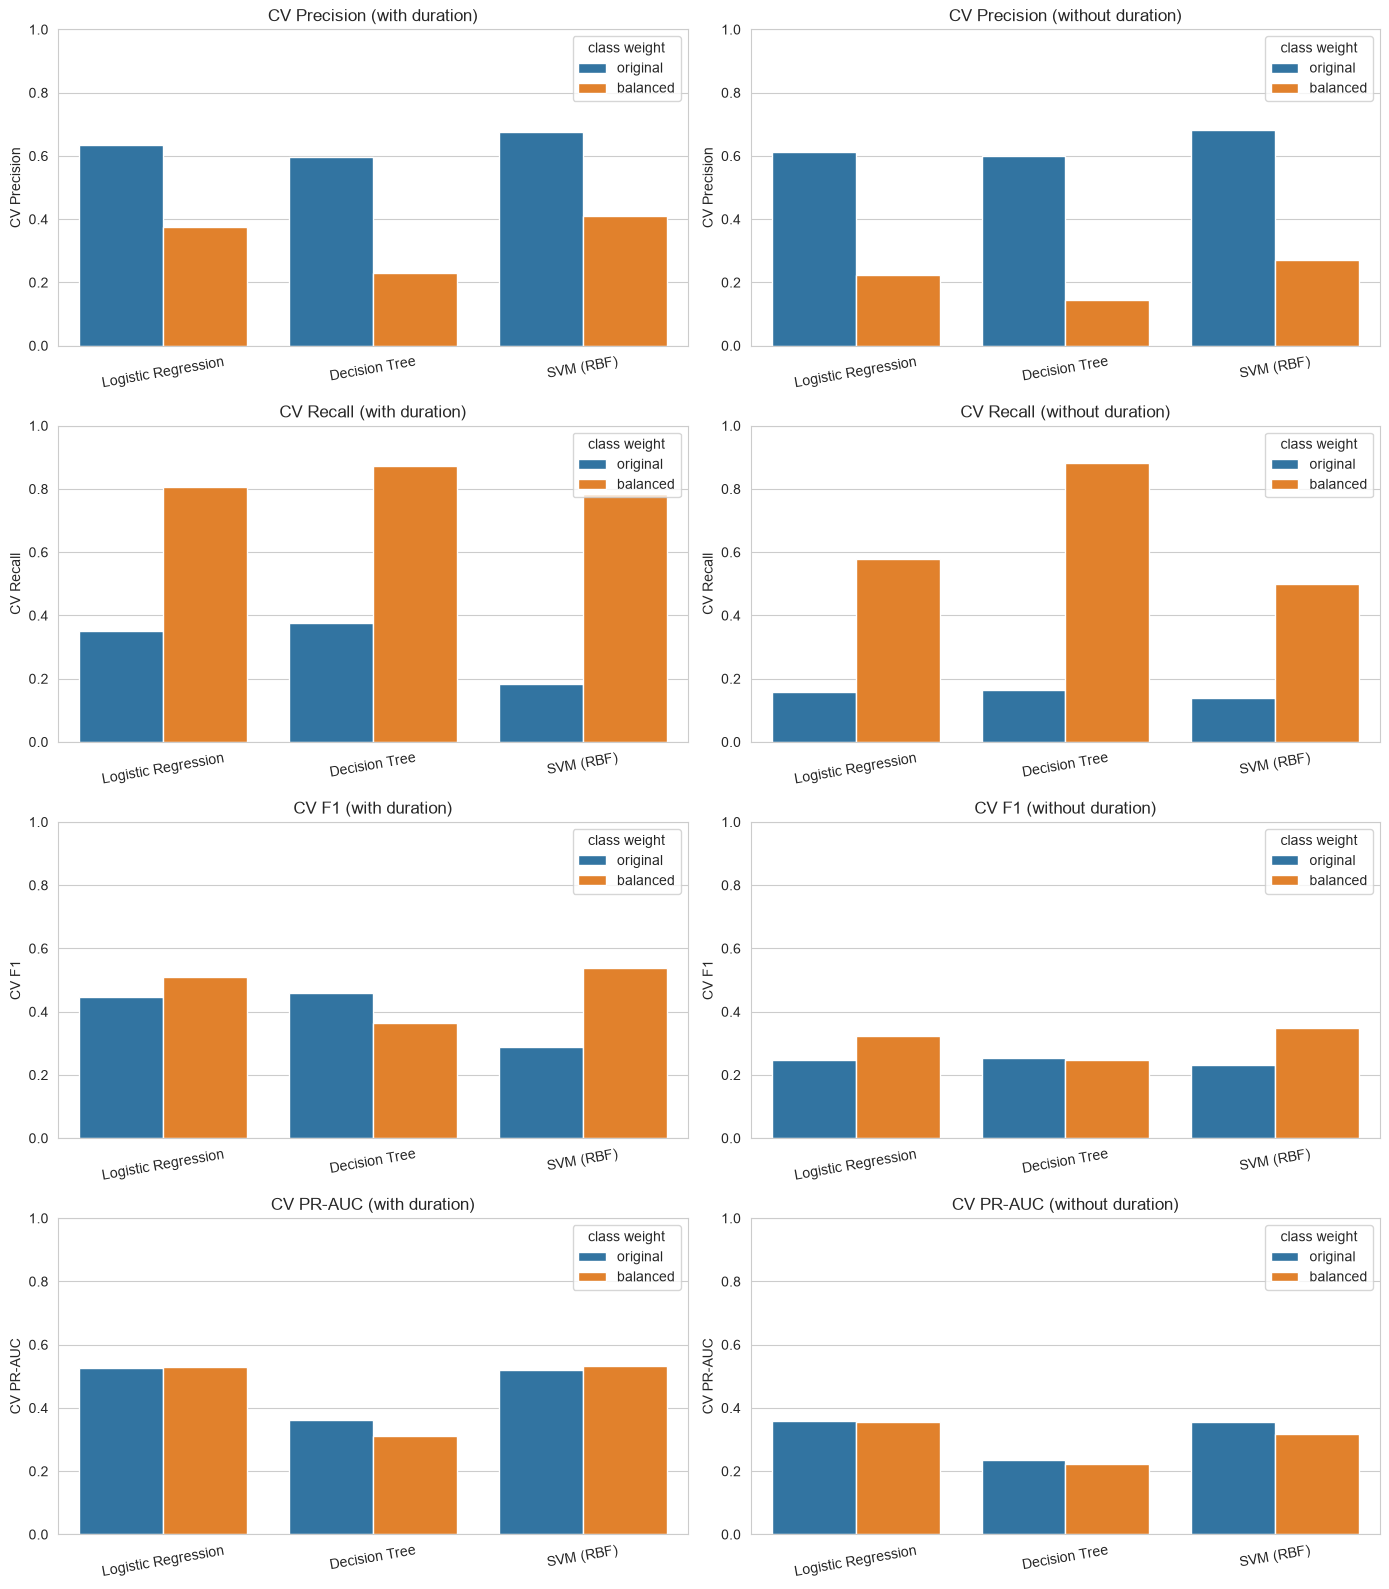

In [27]:
metrics_to_plot = ["CV Precision", "CV Recall", "CV F1", "CV PR-AUC"]
fig, axes = plt.subplots(len(metrics_to_plot), 2, figsize=(14, 16))
for i, metric in enumerate(metrics_to_plot):
    for j, fs in enumerate(feature_sets):
        sub = exp_df[exp_df["feature set"] == fs]
        sns.barplot(data=sub, x="model", y=metric, hue="class weight", ax=axes[i, j])
        axes[i, j].set_title(f"{metric} ({fs})")
        axes[i, j].set_xlabel("")
        axes[i, j].set_ylim(0, 1)
        axes[i, j].tick_params(axis="x", labelrotation=10)
plt.tight_layout()
plt.show()

**问题 A：去掉 `duration`。** 三个模型的 CV F1 都掉得很厉害：

| 模型（原始权重） | 含 duration | 不含 duration | 下降比例 |
|---|---|---|---|
| 逻辑回归 | 0.4478 | 0.2484 | 44.5% |
| 决策树（depth=2） | 0.4594 | 0.2522 | 45.1% |
| SVM | 0.2870 | 0.2307 | 19.6% |

ROC-AUC 也掉了不少，逻辑回归从 0.8942 掉到 0.7205，SVM 从 0.8782 掉到 0.7036。SVM 掉得少，是因为它本来 Recall 就很低（含 duration 时只有 0.18），没多少可掉的。

所以 `duration` 承担了模型的大部分作用。去掉它以后，模型的水平才是拨号前真正能做到的。

**问题 B：类别权重。** 加权以后 Recall 明显上去了，但 Precision 掉得也很多。不含 `duration` 的时候：

- 逻辑回归：Recall 从 0.157 升到 0.580，Precision 从 0.614 降到 0.224，F1 从 0.248 升到 0.323。
- SVM：Recall 从 0.140 升到 0.498，Precision 从 0.682 降到 0.270，F1 从 0.231 升到 0.349。
- 决策树：Recall 从 0.163 升到 0.881，但 Precision 只剩 0.143，F1 从 0.252 降到 0.247。误报太多，抵消了 Recall 的好处。

含 `duration` 的时候，逻辑回归和 SVM 的 F1 分别从 0.448、0.287 升到 0.511、0.538；决策树的 F1 从 0.459 降到 0.363。

所以加权对逻辑回归和 SVM 有用，对决策树没用。

## 6. 模型选择

候选模型是三个模型乘以两种权重，两套特征各 6 个，一共 12 个。选模型的时候只看训练集的交叉验证结果，按 CV F1 最高选。测试集在这一节只用来报告，没有参与选择。

In [28]:
selected = {}
for fs in feature_sets:
    sub = exp_df[exp_df["feature set"] == fs].sort_values("CV F1", ascending=False)
    top = sub.iloc[0]
    selected[fs] = (top["model"], top["class weight"])
    print(f"{fs}: CV F1 最高的是 {top['model']} ({top['class weight']}), CV F1 = {top['CV F1']:.4f}")

with duration: CV F1 最高的是 SVM (RBF) (balanced), CV F1 = 0.5378
without duration: CV F1 最高的是 SVM (RBF) (balanced), CV F1 = 0.3494


In [29]:
candidate_fitted, test_rows = {}, []
for fs, num_cols in feature_sets.items():
    for _, r in exp_df[exp_df["feature set"] == fs].iterrows():
        cw = class_weights[r["class weight"]]
        depth = BEST_DEPTH if r["model"] == "Decision Tree" else None
        pipe = make_pipeline(make_model(r["model"], class_weight=cw, depth=depth), num_cols)
        pipe.fit(X_train, y_train)
        candidate_fitted[(fs, r["model"], r["class weight"])] = pipe
        test_rows.append({
            "feature set": fs,
            "model": r["model"],
            "class weight": r["class weight"],
            "CV F1": r["CV F1"],
            **test_eval(pipe, X_test, y_test),
        })

test_cand_df = pd.DataFrame(test_rows)
display(test_cand_df.sort_values(["feature set", "CV F1"], ascending=[True, False]).round(4))

,feature set,model,class weight,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
5,with duration,SVM (RBF),balanced,0.5378,0.8442,0.4098,0.8077,0.5437,0.8969,0.4826
1,with duration,Logistic Regression,balanced,0.5110,0.8122,0.3590,0.8077,0.4970,0.8901,0.4740
2,with duration,Decision Tree,original,0.4594,0.8873,0.5135,0.3654,0.4270,0.7048,0.3140
0,with duration,Logistic Regression,original,0.4478,0.8917,0.5556,0.2885,0.3797,0.8918,0.4822
3,with duration,Decision Tree,balanced,0.3632,0.6409,0.2298,0.9038,0.3665,0.7991,0.2913
4,with duration,SVM (RBF),original,0.2870,0.8972,0.6897,0.1923,0.3008,0.8740,0.4978
11,without duration,SVM (RBF),balanced,0.3494,0.7956,0.2880,0.5288,0.3729,0.7383,0.3274
7,without duration,Logistic Regression,balanced,0.3229,0.7116,0.2206,0.5962,0.3221,0.7305,0.3247
8,without duration,Decision Tree,original,0.2522,0.8917,0.6000,0.1731,0.2687,0.5881,0.2096
6,without duration,Logistic Regression,original,0.2484,0.8884,0.5517,0.1538,0.2406,0.7329,0.3310


In [30]:
def bootstrap_ci(pipe, X_te, y_te, n_boot=1000):
    rng = np.random.default_rng(RANDOM_STATE)
    y_arr = np.asarray(y_te)
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    stats = {"Recall": [], "F1": [], "PR-AUC": []}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_arr), len(y_arr))
        yt, yp, ys = y_arr[idx], pred[idx], proba[idx]
        if yt.sum() == 0:
            continue
        stats["Recall"].append(recall_score(yt, yp, zero_division=0))
        stats["F1"].append(f1_score(yt, yp, zero_division=0))
        stats["PR-AUC"].append(average_precision_score(yt, ys))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in stats.items()}


for fs, (m, cw) in selected.items():
    ci = bootstrap_ci(candidate_fitted[(fs, m, cw)], X_test, y_test)
    print(f"{fs} / {m} ({cw}) 测试集 95% 置信区间（bootstrap）:")
    for k, (lo, hi) in ci.items():
        print(f"  {k}: [{lo:.4f}, {hi:.4f}]")

with duration / SVM (RBF) (balanced) 测试集 95% 置信区间（bootstrap）:
  Recall: [0.7315, 0.8850]
  F1: [0.4745, 0.6096]
  PR-AUC: [0.3928, 0.5951]
without duration / SVM (RBF) (balanced) 测试集 95% 置信区间（bootstrap）:
  Recall: [0.4347, 0.6182]
  F1: [0.3016, 0.4392]
  PR-AUC: [0.2478, 0.4228]


按 CV F1 排序：

- 含 `duration`：类别加权 SVM（CV F1 0.5378），第二是类别加权逻辑回归（0.5110）。
- 不含 `duration`：类别加权 SVM（CV F1 0.3494），第二是类别加权逻辑回归（0.3229）。

两个场景选出来的都是类别加权的 SVM。测试集上的排名和交叉验证一样，前两名也没有变。

测试集结果（只用来报告）：

- 不含 `duration`，类别加权 SVM：Accuracy 0.7956，Precision 0.2880，Recall 0.5288，F1 0.3729，ROC-AUC 0.7383，PR-AUC 0.3274。
- 不含 `duration`，类别加权逻辑回归：Accuracy 0.7116，Precision 0.2206，Recall 0.5962，F1 0.3221，ROC-AUC 0.7305，PR-AUC 0.3247。
- 含 `duration`，类别加权 SVM：Accuracy 0.8442，Precision 0.4098，Recall 0.8077，F1 0.5437，ROC-AUC 0.8969，PR-AUC 0.4826。

我用 bootstrap（重采样 1000 次）估计了测试集的 95% 置信区间。不含 `duration` 的 SVM，Recall 在 0.435 到 0.618 之间，F1 在 0.302 到 0.439 之间。区间很宽，因为测试集只有 104 个买家。SVM 和逻辑回归的 CV F1 只差 0.03，比区间宽度小很多，所以我认为两个模型差不多。

没有加权的模型在测试集上 Recall 只有 0.13 到 0.17，几乎找不到买家，这也说明加权是有必要的。

## 7. 阈值分析

### 7.1 阈值的选择

营销前筛选这个场景选出来的是类别加权 SVM（不含 `duration`），所以阈值分析也针对它来做。

SVM 有两种输出：`predict_proba` 给的概率，和 `decision_function` 给的分数。默认的分类规则是分数大于 0。我一开始想用概率，但结果不对劲，所以后面都用分数。原因在 7.4 节会讲。用分数的好处是阈值 0 刚好等于默认分类。

阈值只在训练集的 5 折折外预测上选，选 F1 最高的那个。选好以后，我在整个训练集上重新拟合，然后用测试集跑一次。

In [31]:
pre_call_model, pre_call_cw = selected["without duration"]
final_model = make_model(
    pre_call_model,
    class_weight=class_weights[pre_call_cw],
    depth=BEST_DEPTH if pre_call_model == "Decision Tree" else None,
)
final_pipe = make_pipeline(final_model, num_without_duration)
print("阈值分析对象:", pre_call_model, "|", pre_call_cw)

oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(
    final_pipe, X_train, y_train, cv=oof_cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_score = cross_val_predict(
    final_pipe, X_train, y_train, cv=oof_cv, method="decision_function", n_jobs=-1
)

print(f"真实认购比例: {y_train.mean():.4f}")
print(f"默认分类（决策值 > 0）预测为认购的比例: {(oof_score > 0).mean():.4f}")
print(f"概率 >= 0.5 预测为认购的比例: {(oof_proba >= 0.5).mean():.4f}")

阈值分析对象: SVM (RBF) | balanced
真实认购比例: 0.1153
默认分类（决策值 > 0）预测为认购的比例: 0.2121
概率 >= 0.5 预测为认购的比例: 0.0069


In [32]:
grid = np.unique(np.r_[np.quantile(oof_score, np.linspace(0.5, 0.995, 40)), 0.0])
thr_rows = []
for t in grid:
    p = (oof_score >= t).astype(int)
    thr_rows.append({
        "threshold": t,
        "Precision": precision_score(y_train, p, zero_division=0),
        "Recall": recall_score(y_train, p, zero_division=0),
        "F1": f1_score(y_train, p, zero_division=0),
        "flagged rate": p.mean(),
    })
thr_df = pd.DataFrame(thr_rows)
BEST_THRESHOLD = float(thr_df.loc[thr_df["F1"].idxmax(), "threshold"])
display(thr_df.round(4))
print("OOF F1 最高的阈值（决策值）:", round(BEST_THRESHOLD, 4))

,threshold,Precision,Recall,F1,flagged rate
0,-0.6608,0.1748,0.7578,0.2840,0.5000
1,-0.6407,0.1782,0.7530,0.2882,0.4873
2,-0.6227,0.1789,0.7362,0.2879,0.4746
3,-0.6036,0.1826,0.7314,0.2923,0.4618
4,-0.5821,0.1853,0.7218,0.2950,0.4491
5,-0.5559,0.1887,0.7146,0.2986,0.4367
6,-0.5302,0.1898,0.6978,0.2985,0.4239
7,-0.4981,0.1910,0.6811,0.2983,0.4112
8,-0.4753,0.1943,0.6715,0.3014,0.3985
9,-0.4541,0.1964,0.6571,0.3024,0.3858


OOF F1 最高的阈值（决策值）: 0.4534


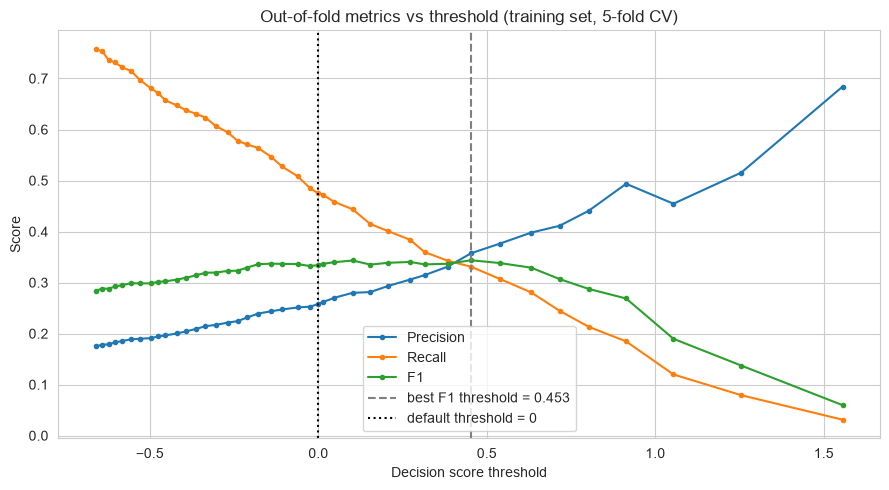

In [33]:
plt.figure(figsize=(9, 5))
plt.plot(thr_df["threshold"], thr_df["Precision"], marker="o", markersize=3, label="Precision")
plt.plot(thr_df["threshold"], thr_df["Recall"], marker="o", markersize=3, label="Recall")
plt.plot(thr_df["threshold"], thr_df["F1"], marker="o", markersize=3, label="F1")
plt.axvline(BEST_THRESHOLD, linestyle="--", color="gray", label=f"best F1 threshold = {BEST_THRESHOLD:.3f}")
plt.axvline(0.0, linestyle=":", color="black", label="default threshold = 0")
plt.xlabel("Decision score threshold")
plt.ylabel("Score")
plt.title("Out-of-fold metrics vs threshold (training set, 5-fold CV)")
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
final_pipe.fit(X_train, y_train)
test_score = final_pipe.decision_function(X_test)

rows = []
for name, t in [("default (0)", 0.0), ("CV-selected", BEST_THRESHOLD)]:
    p = (test_score >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({
        "setting": name,
        "threshold": round(t, 4),
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, zero_division=0),
        "Recall": recall_score(y_test, p, zero_division=0),
        "F1": f1_score(y_test, p, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })
final_thr_df = pd.DataFrame(rows)
display(final_thr_df.round(4))

,setting,threshold,Accuracy,Precision,Recall,F1,TP,FP,FN,TN
0,default (0),0.0000,0.7956,0.2880,0.5288,0.3729,55,136,49,665
1,CV-selected,0.4534,0.8597,0.3905,0.3942,0.3923,41,64,63,737


训练集的折外预测里，默认分类会把 21.2% 的人标成"会买"，而概率大于等于 0.5 的只有 0.7%。差了大概 30 倍，所以概率不能直接拿 0.5 当阈值。

F1 曲线很平。阈值从 0 调到 0.45 左右，折外 F1 只从 0.335 变到 0.344。所以阈值主要是在 Precision 和 Recall 之间换个位置，也就是决定"多打几通电话"还是"少漏掉几个人"，而不是让 F1 明显变好。

按 F1 选出的阈值是 0.4534，折外的 F1 是 0.344，Precision 0.358，Recall 0.331。

测试集上的结果如下：

| 设置 | 阈值 | 判为会买的人数 | TP | FP | FN | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 默认 | 0 | 191 | 55 | 136 | 49 | 0.288 | 0.529 | 0.373 |
| 交叉验证选的 | 0.4534 | 105 | 41 | 64 | 63 | 0.391 | 0.394 | 0.392 |

阈值提高以后，要打的电话从 191 通降到 105 通，少打了 45%。找到的买家从 55 个降到 41 个，少了 14 个，大约是 25%。Precision 从 0.288 提高到 0.391，是随机打电话（基础比例 0.115）的 3.4 倍。

如果打一通电话很便宜，多打一些、多找一些买家可能更划算；如果电话成本高，就应该用更高的阈值。到底选哪个，取决于成本，所以下面做了成本比的敏感性分析。

### 7.2 成本比的敏感性分析

前面选阈值的时候，相当于默认"漏掉一个买家"和"多打一通电话"的代价一样。实际上两者可能差很多。所以我把成本比（漏掉一个买家的代价 ÷ 多打一通电话的代价）设成 1、2、3、5、10、20，看最优阈值怎么变。

题目没有给实际成本，这里的比值是我假设的，所以这一节主要看趋势，不是给出真正的最优解。每个成本比下，我都用训练集的折外分数，找期望成本最低的阈值。

In [35]:
y_tr = y_train.to_numpy()


def expected_cost(score, t, r):
    p = score >= t
    fp = np.sum(p & (y_tr == 0))
    fn = np.sum((~p) & (y_tr == 1))
    return (fp + r * fn) / len(y_tr)


cost_grid = np.unique(np.r_[np.quantile(oof_score, np.linspace(0, 0.995, 200)), 0.0])
cost_rows = []
for r in [1, 2, 3, 5, 10, 20]:
    costs = np.array([expected_cost(oof_score, t, r) for t in cost_grid])
    k = int(np.argmin(costs))
    t_star = cost_grid[k]
    p = oof_score >= t_star
    cost_rows.append({
        "FN/FP cost ratio": r,
        "best threshold": round(float(t_star), 4),
        "flagged rate": p.mean(),
        "recall": recall_score(y_tr, p, zero_division=0),
        "precision": precision_score(y_tr, p, zero_division=0),
        "cost per customer (best)": costs[k],
        "cost per customer (default 0)": expected_cost(oof_score, 0.0, r),
    })
cost_df = pd.DataFrame(cost_rows)
cost_df["saving vs default (%)"] = (
    1 - cost_df["cost per customer (best)"] / cost_df["cost per customer (default 0)"]
) * 100
display(cost_df.round(4))

,FN/FP cost ratio,best threshold,flagged rate,recall,precision,cost per customer (best),cost per customer (default 0),saving vs default (%)
0,1,1.4129,0.0102,0.0528,0.5946,0.1134,0.2179,47.9695
1,2,0.8435,0.0501,0.2014,0.4641,0.2110,0.2785,24.2304
2,3,0.6677,0.0752,0.2686,0.4118,0.2973,0.3390,12.3165
3,5,0.0730,0.1900,0.4532,0.2751,0.4530,0.4602,1.5625
4,10,-0.5550,0.4350,0.7146,0.1894,0.6817,0.7630,10.6560
5,20,-1.2933,0.8899,0.9640,0.1249,0.8617,1.3686,37.0378


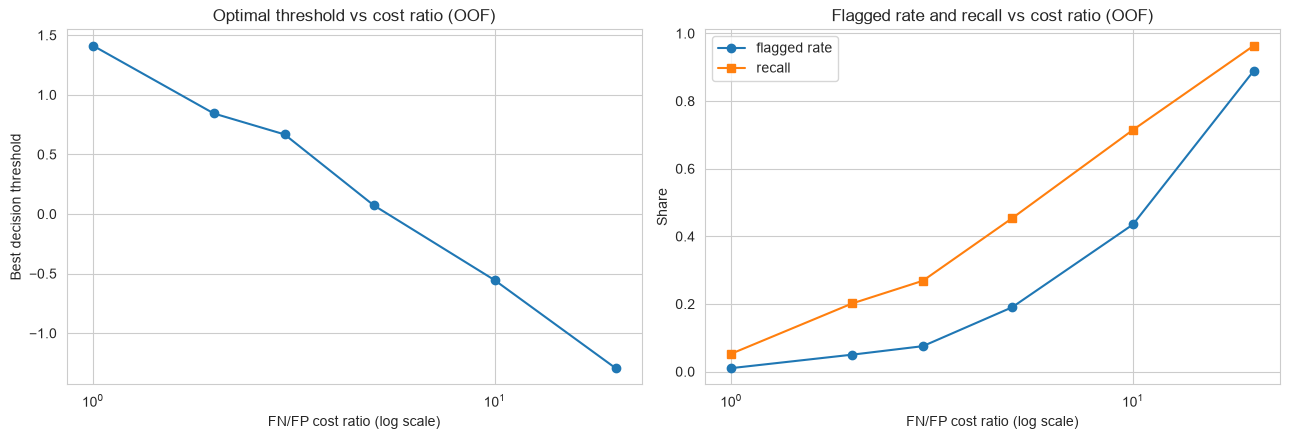

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(cost_df["FN/FP cost ratio"], cost_df["best threshold"], marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("FN/FP cost ratio (log scale)")
axes[0].set_ylabel("Best decision threshold")
axes[0].set_title("Optimal threshold vs cost ratio (OOF)")

axes[1].plot(cost_df["FN/FP cost ratio"], cost_df["flagged rate"], marker="o", label="flagged rate")
axes[1].plot(cost_df["FN/FP cost ratio"], cost_df["recall"], marker="s", label="recall")
axes[1].set_xscale("log")
axes[1].set_xlabel("FN/FP cost ratio (log scale)")
axes[1].set_ylabel("Share")
axes[1].set_title("Flagged rate and recall vs cost ratio (OOF)")
axes[1].legend()
plt.tight_layout()
plt.show()

- 成本比为 1（漏掉一个买家和多打一通电话一样糟）时，最优阈值是 1.41，只打 1% 的人。这是因为买家本来只占 11.5%，如果两种错误的代价一样，模型多打出来的误报反而不划算，还不如少打。
- 成本比为 5 时，最优阈值是 0.073，打电话的比例是 19%，和默认阈值 0 的 21% 很接近，省下的成本只有 1.6%。也就是说，默认的类别加权 SVM 大致相当于假设"漏掉一个买家的代价是多打一通电话的 5 倍左右"。
- 成本比为 10 时，要打 43.5% 的人；成本比为 20 时，要打 89% 的人。这时宁可多打也不能漏。

所以阈值确实取决于成本假设，最优阈值从 1.41 一直变到 -1.29，跨度很大，没有办法给出一个绝对正确的阈值。如果银行能提供实际的电话成本和单个客户的收益，就可以直接代入这个表，找到对应的阈值。

### 7.3 Lift 与 Gain 曲线

电话营销一般是按模型给客户打分，从高分到低分打电话，打到哪里为止要看效果。Gain 曲线回答的是"打前 x% 的客户，能找到多少比例的买家"；Lift 是把这个比例除以随机打电话时的比例，数值越大越好。

这一节用的是测试集，只用来描述排序效果，不用来重新选阈值。我还拟合了一个类别加权的逻辑回归做对比，两个模型都只用不含 `duration` 的特征。

In [37]:
lr_bal_pipe = make_pipeline(make_model("Logistic Regression", class_weight="balanced"), num_without_duration)
lr_bal_pipe.fit(X_train, y_train)
lr_bal_score = lr_bal_pipe.decision_function(X_test)


def gain_table(score, y_true, n_bins=10):
    y_arr = np.asarray(y_true)
    order = np.argsort(-score)
    y_sorted = y_arr[order]
    n, n_pos = len(y_sorted), y_arr.sum()
    rows = []
    for k in range(1, n_bins + 1):
        m = int(round(n * k / n_bins))
        captured = y_sorted[:m].sum()
        rows.append({
            "contacted share": k / n_bins,
            "buyers reached": int(captured),
            "gain (recall)": captured / n_pos,
            "lift": (captured / m) / (n_pos / n),
        })
    return pd.DataFrame(rows)


gain_svm = gain_table(test_score, y_test)
gain_lr = gain_table(lr_bal_score, y_test)
lift_table = pd.concat(
    {
        "SVM (balanced)": gain_svm.set_index("contacted share"),
        "LR (balanced)": gain_lr.set_index("contacted share"),
    },
    axis=1,
)
display(lift_table.round(3))

op_share = (test_score >= BEST_THRESHOLD).mean()
print(f"CV 阈值下打电话的比例（测试集）: {op_share:.4f}")

SVM (balanced)                       LR (balanced)                     
                buyers reached gain (recall)   lift buyers reached gain (recall)   lift
contacted share                                                                        
0.1                         34         0.327  3.287             33         0.317  3.191
0.2                         51         0.490  2.452             50         0.481  2.404
0.3                         66         0.635  2.111             62         0.596  1.984
0.4                         71         0.683  1.707             70         0.673  1.683
0.5                         81         0.779  1.559             77         0.740  1.482
0.6                         86         0.827  1.378             85         0.817  1.362
0.7                         92         0.885  1.263             92         0.885  1.263
0.8                         97         0.933  1.166            100         0.962  1.202
0.9                        100         0.962  1.069            103         0.990  1.101
1.0                        104         1.000  1.000            104         1.000  1.000

CV 阈值下打电话的比例（测试集）: 0.1160


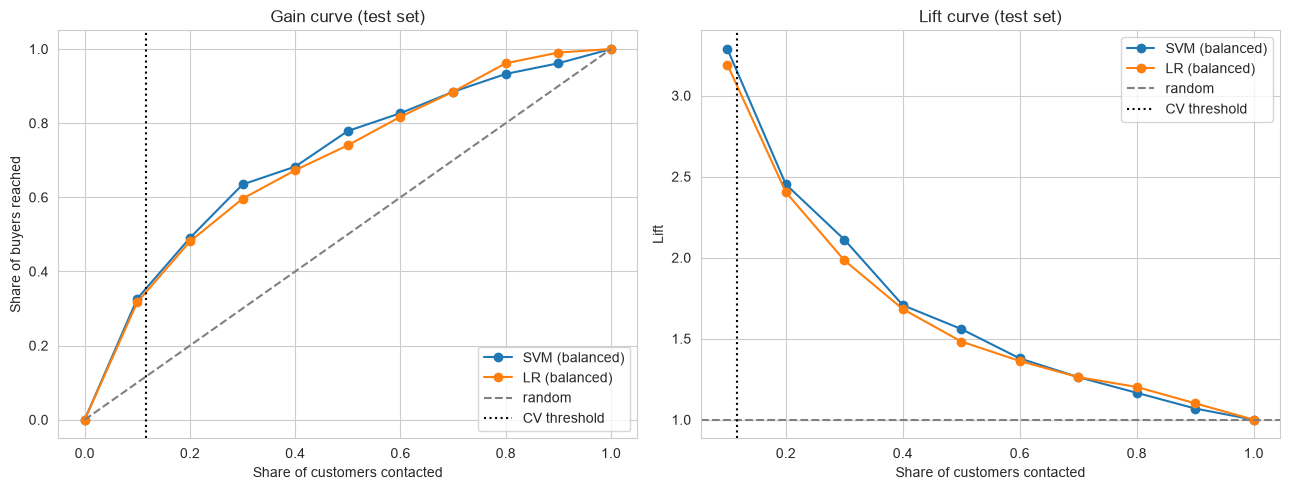

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, g in [("SVM (balanced)", gain_svm), ("LR (balanced)", gain_lr)]:
    xs = np.r_[0, g["contacted share"].to_numpy()]
    ys = np.r_[0, g["gain (recall)"].to_numpy()]
    axes[0].plot(xs, ys, marker="o", label=name)
    axes[1].plot(g["contacted share"], g["lift"], marker="o", label=name)

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="random")
axes[0].axvline(op_share, linestyle=":", color="black", label="CV threshold")
axes[0].set_xlabel("Share of customers contacted")
axes[0].set_ylabel("Share of buyers reached")
axes[0].set_title("Gain curve (test set)")
axes[0].legend()

axes[1].axhline(1, linestyle="--", color="gray", label="random")
axes[1].axvline(op_share, linestyle=":", color="black", label="CV threshold")
axes[1].set_xlabel("Share of customers contacted")
axes[1].set_ylabel("Lift")
axes[1].set_title("Lift curve (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

Gain 和 Lift 都是用测试集算的，主要看模型的排序能力。

打前 10%（大约 90 人）的客户，SVM 能找到 34 个买家，占全部买家的 32.7%，Lift 是 3.29。打前 20% 能找到 49%，打前 30% 能找到 63.5%。打的比例越大，Lift 越低，这是正常的。

和类别加权逻辑回归比，SVM 在前 30% 里略好一些（66 个对 62 个）。再往后两者就差不多了，所以排序上两个模型的差别不大。

阈值选出来的打电话比例是 11.6%，正好落在 10% 和 20% 之间。这个点上 SVM 能找到 41 个买家，占 39.4%，Lift 是 3.4，和 7.1 节的结果是一致的。

### 7.4 校准

7.1 里我发现 SVM 给出的概率和默认分类对不上。这一节画校准曲线，看看各个模型给出的概率是不是"靠谱"。

横轴是模型给出的平均概率，纵轴是这些样本里实际买的比例。如果模型校准得好，点应该落在对角线上。另外我还算了 Brier score，它越小越好。

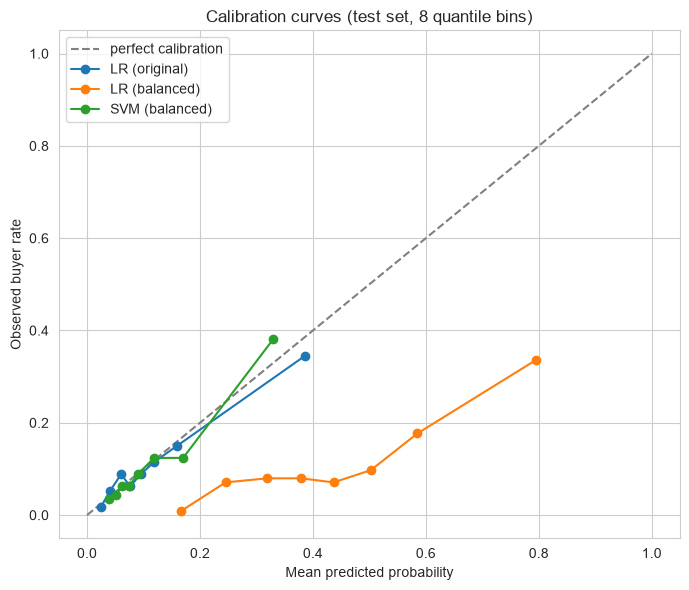

,model,mean predicted probability,actual buyer rate,Brier score
0,LR (original),0.1202,0.1149,0.0909
1,LR (balanced),0.4284,0.1149,0.2005
2,SVM (balanced),0.1166,0.1149,0.0905


OOF 中决策分数接近 0 的样本，对应概率的中位数: 0.1552


In [39]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

lr_orig_pipe = make_pipeline(make_model("Logistic Regression"), num_without_duration)
lr_orig_pipe.fit(X_train, y_train)

prob_models = {
    "LR (original)": lr_orig_pipe.predict_proba(X_test)[:, 1],
    "LR (balanced)": lr_bal_pipe.predict_proba(X_test)[:, 1],
    "SVM (balanced)": final_pipe.predict_proba(X_test)[:, 1],
}

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
cal_rows = []
for name, p in prob_models.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
    cal_rows.append({
        "model": name,
        "mean predicted probability": p.mean(),
        "actual buyer rate": y_test.mean(),
        "Brier score": brier_score_loss(y_test, p),
    })
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed buyer rate")
ax.set_title("Calibration curves (test set, 8 quantile bins)")
ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(cal_rows).round(4))

near0 = np.abs(oof_score) < 0.05
print("OOF 中决策分数接近 0 的样本，对应概率的中位数:", round(float(np.median(oof_proba[near0])), 4))

- 原始逻辑回归的平均预测概率是 0.120，实际买的比例是 0.115，Brier score 是 0.0909，校准得比较好。
- 类别加权逻辑回归的平均概率是 0.428，比实际高了将近 4 倍，Brier score 涨到 0.2005。加了类别权重以后，它的概率已经不能当成"买的可能性"来看了。
- 类别加权 SVM 的平均概率是 0.117，和实际比例很接近，Brier score 是 0.0905，和原始逻辑回归差不多。

针对 7.1 里用 0.5 当阈值会出问题，我的理解是这样的：SVM 的概率是用没有加权的标签做 Platt 校准得到的，所以它的平均值会贴近真实比例。类别加权只是把决策边界移到了别的位置。我算了一下，决策分数接近 0 的样本，对应的概率中位数是 0.155。也就是说，默认分类的边界其实对应大约 15% 的概率，远低于 0.5。

这说明类别加权 SVM 更适合用来排序，而不适合直接拿概率算期望收益。如果以后真的需要概率，可以在加权之后再做一次校准。

**营销前筛选（不含 `duration`）。** 推荐类别加权的 SVM（RBF 核），阈值取 0.4534（决策分数）。理由有三点：

1. 交叉验证里它的 F1 最高（0.3494），测试集上的排名也是第一。
2. 测试集上按这个阈值打 105 通电话（占 11.6%），能找到 41 个买家，Precision 是 0.39，是随机打的 3.4 倍。从 Lift 曲线看，前 10% 的客户里就有大约三分之一的买家。
3. 和默认分类相比，少打了 45% 的电话，只少找到 14 个买家。

如果银行更看重可解释性，类别加权的逻辑回归也可以用。它的 CV F1 只低 0.03，测试集的排序和 SVM 很接近，只是前 30% 略差一点。

阈值具体取多少，要看银行的成本。从成本比分析看，成本比在 5 左右时默认阈值已经接近最优。如果漏掉一个买家的代价明显更大，就应该多打一些电话。这需要业务部门提供实际数据。

**通话后跟进（含 `duration`）。** 这个场景可以用类别加权 SVM，测试集 Recall 是 0.81，F1 是 0.54，适合在通话结束后优先跟进最可能买的客户。但 `duration` 在拨号前是未知的，所以这个模型不能用来决定打不打电话。

**实际中可能的问题。**

- 数据只有 4521 条，买家只有 521 个，测试集里只有 104 个买家。结果的置信区间很宽，比如不含 `duration` 的 SVM，测试集 F1 的 95% 区间是 [0.30, 0.44]。
- 数据是历史记录，营销环境变化以后，模型需要重新验证。
- 成本比是我假设的，真实的电话成本和客户收益我都没有。
- 按职业、婚姻这些特征筛选客户，要注意公平性，不能对某些群体造成系统性的不利。
- 模型上线以后要定期监控效果，因为客户结构和营销策略都会变化。
- 我只做了一次 8:2 划分，SVM 的 C 和 gamma 用的是默认值，也没有试随机森林、梯度提升之类的模型。这些都可以作为以后的改进方向。

## AI 使用说明

初版的代码和文字用了 AI 辅助工具（`jupyter_cc`，内层模型为 DeepSeek-V4.1-Flash-1017），主要帮忙改报错、写绘图代码，也整理过一部分文字。建模思路、实验设计、特征处理方式和结果分析是我自己定的。

修改阶段，我用 AI 编程助手（OpenCode，模型为 Claude Haiku 5.5）检查代码问题，帮忙改了预处理和交叉验证的写法、阈值分析的方法，以及一部分文字。AI 给的修改建议我都看过、决定是否采用。